# Model3 · Predicción de concentración autorreportada (versión corregida de Model2)

**Pregunta:** ¿qué tanto predicen las señales (emociones faciales, fisiología y EEG) la concentración que reporta el participante, **comparado con solo saber qué tarea está haciendo**?

### Qué cambia respecto a `Model2.ipynb`
| | Model2 | Model3 |
|---|---|---|
| Etiqueta | `Selfreport_focus >= 3`, incluyendo `focus = 0` como "no concentrado" | Se eliminan las filas con `focus = 0` (NA: perfil, instrucciones, encuestas) y las secciones de autorreporte (`Task_Type = 0`). Umbral configurable (por defecto ≥ 4) |
| Unidad de análisis | 1 fila = 1 segundo | Ventanas de 10 s (como en `PCA_exploratoryAnalisis.ipynb`) |
| Normalización | Ninguna | z-score **por participante** (cada persona contra sí misma) |
| Validación | 1 partición (~8 personas en test) | **GroupKFold de 5 particiones**: todas las personas se prueban una vez, siempre sin haber sido vistas |
| Comparación | Ninguna | Modelos base: clase mayoritaria, solo tarea, solo tiempo |
| Modelos | TabNet | Regresión logística, random forest y TabNet (misma configuración que Model2) |

**Parte 1** (secciones 1–10): modelos y comparación contra modelos base.  
**Parte 2** (secciones 11–19): hiperparámetros y gráficas de la regresión logística.

> ⚠️ Datos confidenciales del IFE: no subir este notebook con salidas a repositorios públicos.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import GroupKFold, GroupShuffleSplit
from sklearn.metrics import roc_auc_score, balanced_accuracy_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier

In [2]:
# ---------------- Configuración ----------------
CSV_PATH = "NPFC-Test_Database_V2.csv"
UMBRAL_FOCUS = 4        # focus >= UMBRAL -> concentrado (1). Probar también 3
VENTANA_S = 10          # segundos por ventana
N_SPLITS = 5            # particiones por participante
RANDOM_STATE = 42
USAR_TABNET = True      # False para correr solo los modelos de sklearn (más rápido)

sns.set_theme(style="whitegrid", context="notebook")

## 1. Cargar datos y variables (iguales a Model2)

In [3]:
NPFC = pd.read_csv(CSV_PATH, low_memory=False)

bands = ['Delta', 'Theta', 'Alpha', 'Beta', 'Gamma']
for band in bands:
    NPFC[band] = NPFC[[f'{band}_TP9', f'{band}_AF7', f'{band}_AF8', f'{band}_TP10']].mean(axis=1)

eeg_features = bands
emotion_cols = ['resmasknet_anger', 'resmasknet_disgust', 'resmasknet_fear', 'resmasknet_happiness',
                'resmasknet_sadness', 'resmasknet_surprise', 'resmasknet_neutral']
physio_cols = ['EDA', 'BVP', 'Temperature']
feature_cols = emotion_cols + physio_cols + eeg_features

# Segundos desde el inicio de la prueba (1 fila = 1 s); se usa solo como modelo base
NPFC['Segundo'] = NPFC.groupby('Subject_ID').cumcount()
print(NPFC.shape)

(47905, 72)


## 2. Corregir la etiqueta

`Selfreport_focus = 0` significa **"no hubo pregunta"** (perfil, instrucciones, encuestas), no "nada concentrado". En Model2 esas filas quedaban como clase 0.

In [4]:
diego = NPFC.dropna(subset=feature_cols).copy()
diego['Category'] = (diego['Selfreport_focus'] >= 3).astype(int)
clase0 = diego[diego['Category'] == 0]
print(f"Etiqueta de Model2: {diego['Category'].mean():.0%} positivos")
print(f"De la clase 0 de Model2, {(clase0['Selfreport_focus'] == 0).mean():.0%} eran filas sin respuesta (focus = 0)\n")

df = NPFC.dropna(subset=feature_cols).copy()
df = df[(df['Selfreport_focus'] > 0) & (df['Task_Type'] != 0)]   # solo tareas con estímulo y con respuesta
print(f"Filas útiles: {len(df):,} | participantes: {df['Subject_ID'].nunique()}")
print("Distribución de focus (1-5):", df['Selfreport_focus'].value_counts().sort_index().to_dict())

Etiqueta de Model2: 69% positivos
De la clase 0 de Model2, 43% eran filas sin respuesta (focus = 0)

Filas útiles: 33,636 | participantes: 39
Distribución de focus (1-5): {1: 1337, 2: 5775, 3: 8790, 4: 10231, 5: 7503}


## 3. Normalizar por participante y agrupar en ventanas de 10 s

- **Normalización por participante:** a cada variable se le resta la media de esa persona y se divide entre su desviación. Así el modelo no puede usar "quién es" (por ejemplo, la temperatura de su muñeca) para adivinar.
- **Ventanas de 10 s:** el autorreporte se contesta una vez por tarea, así que no tiene sentido tratar cada segundo como un ejemplo independiente. Promediar reduce ruido.

La normalización usa todos los datos de cada persona, también de las personas de prueba. Es válido porque no usa la etiqueta: en la práctica, se calibraría a cada persona con sus propios datos.

In [5]:
dz = df.copy()
for c in feature_cols:
    dz[c] = df.groupby('Subject_ID')[c].transform(lambda x: (x - x.mean()) / (x.std() if x.std() > 0 else 1))

dz['Ventana'] = dz.groupby(['Subject_ID', 'Task_Num']).cumcount() // VENTANA_S
w = (dz.groupby(['Subject_ID', 'Task_Num', 'Ventana'])
       .agg({**{c: 'mean' for c in feature_cols}, 'Selfreport_focus': 'first', 'Segundo': 'mean'})
       .reset_index())
w['Category'] = (w['Selfreport_focus'] >= UMBRAL_FOCUS).astype(int)
w['Task_Num_str'] = w['Task_Num'].astype(str)

groups = w['Subject_ID'].values
y = w['Category'].values
print(f"Ventanas: {len(w):,} | participantes: {w['Subject_ID'].nunique()} | concentrado (focus >= {UMBRAL_FOCUS}): {y.mean():.0%}")
print("\nFocus promedio por tarea (por eso 'solo tarea' es un modelo base fuerte):")
print(w.groupby('Task_Num')['Selfreport_focus'].mean().round(2).to_string())

Ventanas: 3,577 | participantes: 39 | concentrado (focus >= 4): 54%

Focus promedio por tarea (por eso 'solo tarea' es un modelo base fuerte):
Task_Num
2.1    2.90
3.1    4.25
4.1    2.74
5.1    4.53
5.2    4.52
5.3    4.56
5.4    4.56
6.1    3.33
7.2    3.80
7.3    3.81
7.4    3.81
8.1    3.61


## 4. Evaluación con GroupKFold

Cada participante cae en prueba exactamente una vez, y nunca está en entrenamiento al mismo tiempo. Se reporta el AUC de cada partición (0.5 = azar, 1 = perfecto) y la *balanced accuracy*.

In [6]:
gkf = GroupKFold(n_splits=N_SPLITS)
FOLDS = list(gkf.split(w, y, groups))

def evaluar(nombre, hacer_modelo, cols):
    aucs, baccs = [], []
    for tr, te in FOLDS:
        m = hacer_modelo()
        m.fit(w.iloc[tr][cols], y[tr])
        p = m.predict_proba(w.iloc[te][cols])[:, 1]
        aucs.append(roc_auc_score(y[te], p))
        baccs.append(balanced_accuracy_score(y[te], (p >= 0.5).astype(int)))
    return {'Modelo': nombre, 'AUC': np.mean(aucs), 'AUC_sd': np.std(aucs),
            'Balanced acc': np.mean(baccs), 'AUC por partición': np.round(aucs, 2)}

def logreg():   return make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, class_weight='balanced'))
def rforest():  return RandomForestClassifier(n_estimators=300, min_samples_leaf=10, class_weight='balanced',
                                              random_state=RANDOM_STATE, n_jobs=-1)
def solo_tarea():
    return make_pipeline(OneHotEncoder(handle_unknown='ignore'), LogisticRegression(max_iter=2000, class_weight='balanced'))

sin_temp = [c for c in feature_cols if c != 'Temperature']

resultados = [
    evaluar('BASE · clase mayoritaria',      lambda: DummyClassifier(strategy='most_frequent'), ['Segundo']),
    evaluar('BASE · solo tipo de tarea',     solo_tarea, ['Task_Num_str']),
    evaluar('BASE · solo segundo de la prueba', rforest, ['Segundo']),
    evaluar('Regresión logística · todas',   logreg,  feature_cols),
    evaluar('Regresión logística · sin temperatura', logreg, sin_temp),
    evaluar('Regresión logística · solo EEG', logreg, eeg_features),
    evaluar('Random forest · todas',          rforest, feature_cols),
]
pd.DataFrame(resultados).set_index('Modelo').round(3)

,AUC,AUC_sd,Balanced acc,AUC por partición
Modelo,,,,
BASE · clase mayoritaria,0.500,0.000,0.500,"[0.5, 0.5, 0.5, 0.5, 0.5]"
BASE · solo tipo de tarea,0.800,0.090,0.721,"[0.89, 0.83, 0.7, 0.9, 0.69]"
BASE · solo segundo de la prueba,0.702,0.064,0.657,"[0.69, 0.75, 0.61, 0.79, 0.67]"
Regresión logística · todas,0.651,0.053,0.606,"[0.61, 0.67, 0.68, 0.72, 0.57]"
Regresión logística · sin temperatura,0.610,0.037,0.576,"[0.58, 0.6, 0.63, 0.67, 0.57]"
Regresión logística · solo EEG,0.566,0.048,0.547,"[0.5, 0.57, 0.65, 0.54, 0.57]"
Random forest · todas,0.610,0.045,0.579,"[0.57, 0.67, 0.58, 0.66, 0.57]"


## 5. TabNet (misma configuración que Model2)

En cada partición, el entrenamiento se divide otra vez por participante para tener un conjunto de validación (early stopping). El conjunto de prueba nunca se usa para entrenar ni para elegir la época. Se ajustó `batch_size` porque ahora hay ~3,500 ventanas en lugar de ~47 mil segundos.

In [7]:
tabnet_imp = []
if USAR_TABNET:
    import torch
    from pytorch_tabnet.tab_model import TabNetClassifier

    aucs, baccs = [], []
    for k, (tr, te) in enumerate(FOLDS):
        X_tr_all, y_tr_all, g_tr = w.iloc[tr][feature_cols].values, y[tr], groups[tr]
        X_te, y_te = w.iloc[te][feature_cols].values, y[te]
        itr, iva = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=RANDOM_STATE).split(X_tr_all, y_tr_all, g_tr))
        sc = StandardScaler().fit(X_tr_all[itr])
        X_train, X_valid, X_test = sc.transform(X_tr_all[itr]), sc.transform(X_tr_all[iva]), sc.transform(X_te)

        clf = TabNetClassifier(
            n_d=16, n_a=16, n_steps=4, gamma=1.5, lambda_sparse=1e-4,
            optimizer_fn=torch.optim.Adam, optimizer_params=dict(lr=2e-2),
            scheduler_params={"step_size": 10, "gamma": 0.9}, scheduler_fn=torch.optim.lr_scheduler.StepLR,
            mask_type='entmax', seed=RANDOM_STATE, verbose=0)
        clf.fit(X_train=X_train, y_train=y_tr_all[itr],
                eval_set=[(X_valid, y_tr_all[iva])], eval_name=['valid'], eval_metric=['auc'],
                max_epochs=200, patience=20, batch_size=256, virtual_batch_size=64, weights=1)
        p = clf.predict_proba(X_test)[:, 1]
        aucs.append(roc_auc_score(y_te, p))
        baccs.append(balanced_accuracy_score(y_te, (p >= 0.5).astype(int)))
        tabnet_imp.append(clf.feature_importances_)
        print(f"Partición {k + 1}: AUC test = {aucs[-1]:.3f} (mejor época {clf.best_epoch})")

    resultados.append({'Modelo': 'TabNet · todas', 'AUC': np.mean(aucs), 'AUC_sd': np.std(aucs),
                       'Balanced acc': np.mean(baccs), 'AUC por partición': np.round(aucs, 2)})


Early stopping occurred at epoch 56 with best_epoch = 36 and best_valid_auc = 0.66749
Partición 1: AUC test = 0.555 (mejor época 36)


/Users/mariamartinez/miniconda3/lib/python3.13/site-packages/pytorch_tabnet/callbacks.py:172: UserWarning: Best weights from best epoch are automatically used!
  warnings.warn(wrn_msg)



Early stopping occurred at epoch 36 with best_epoch = 16 and best_valid_auc = 0.69351
Partición 2: AUC test = 0.611 (mejor época 16)


/Users/mariamartinez/miniconda3/lib/python3.13/site-packages/pytorch_tabnet/callbacks.py:172: UserWarning: Best weights from best epoch are automatically used!
  warnings.warn(wrn_msg)



Early stopping occurred at epoch 35 with best_epoch = 15 and best_valid_auc = 0.62783
Partición 3: AUC test = 0.625 (mejor época 15)


/Users/mariamartinez/miniconda3/lib/python3.13/site-packages/pytorch_tabnet/callbacks.py:172: UserWarning: Best weights from best epoch are automatically used!
  warnings.warn(wrn_msg)



Early stopping occurred at epoch 23 with best_epoch = 3 and best_valid_auc = 0.70176
Partición 4: AUC test = 0.569 (mejor época 3)


/Users/mariamartinez/miniconda3/lib/python3.13/site-packages/pytorch_tabnet/callbacks.py:172: UserWarning: Best weights from best epoch are automatically used!
  warnings.warn(wrn_msg)



Early stopping occurred at epoch 63 with best_epoch = 43 and best_valid_auc = 0.64723
Partición 5: AUC test = 0.595 (mejor época 43)


/Users/mariamartinez/miniconda3/lib/python3.13/site-packages/pytorch_tabnet/callbacks.py:172: UserWarning: Best weights from best epoch are automatically used!
  warnings.warn(wrn_msg)


## 6. ¿Las señales agregan algo además de la tarea?

La pregunta clave: si ya sabemos qué tarea es, ¿las señales ayudan a predecir *quién* se sintió más o menos concentrado en ella? Se compara "solo tarea" contra "tarea + señales".

In [8]:
def tarea_mas_senales():
    from sklearn.compose import ColumnTransformer
    pre = ColumnTransformer([('tarea', OneHotEncoder(handle_unknown='ignore'), ['Task_Num_str']),
                             ('senales', StandardScaler(), feature_cols)])
    return make_pipeline(pre, LogisticRegression(max_iter=2000, class_weight='balanced'))

resultados.append(evaluar('Tarea + señales (regresión logística)', tarea_mas_senales, ['Task_Num_str'] + feature_cols))

## 7. Resultados

,AUC,AUC_sd,Balanced acc,AUC por partición
Modelo,,,,
BASE · clase mayoritaria,0.500,0.000,0.500,"[0.5, 0.5, 0.5, 0.5, 0.5]"
BASE · solo tipo de tarea,0.800,0.090,0.721,"[0.89, 0.83, 0.7, 0.9, 0.69]"
BASE · solo segundo de la prueba,0.702,0.064,0.657,"[0.69, 0.75, 0.61, 0.79, 0.67]"
Regresión logística · todas,0.651,0.053,0.606,"[0.61, 0.67, 0.68, 0.72, 0.57]"
Regresión logística · sin temperatura,0.610,0.037,0.576,"[0.58, 0.6, 0.63, 0.67, 0.57]"
Regresión logística · solo EEG,0.566,0.048,0.547,"[0.5, 0.57, 0.65, 0.54, 0.57]"
Random forest · todas,0.610,0.045,0.579,"[0.57, 0.67, 0.58, 0.66, 0.57]"
TabNet · todas,0.591,0.026,0.577,"[0.55, 0.61, 0.62, 0.57, 0.59]"
Tarea + señales (regresión logística),0.791,0.064,0.728,"[0.81, 0.81, 0.72, 0.89, 0.73]"


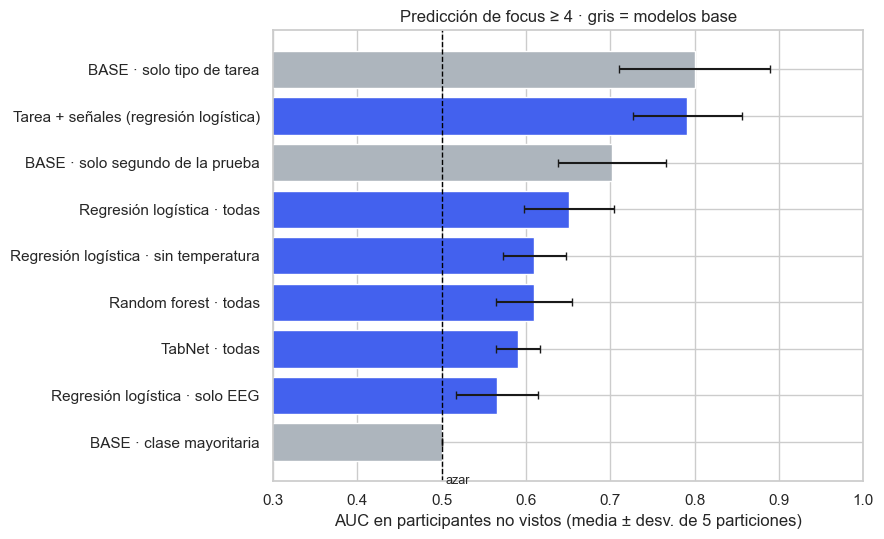

In [9]:
res = pd.DataFrame(resultados).set_index('Modelo')
display(res.round(3))

orden = res.sort_values('AUC').index
colores = ['#adb5bd' if m.startswith('BASE') else '#4361ee' for m in orden]
fig, ax = plt.subplots(figsize=(9, 0.45 * len(orden) + 1.5))
ax.barh(orden, res.loc[orden, 'AUC'], xerr=res.loc[orden, 'AUC_sd'], color=colores, capsize=3)
ax.axvline(0.5, color='black', ls='--', lw=1)
ax.text(0.505, -0.9, 'azar', fontsize=9)
ax.set_xlim(0.3, 1.0)
ax.set_xlabel(f'AUC en participantes no vistos (media ± desv. de {N_SPLITS} particiones)')
ax.set_title(f'Predicción de focus ≥ {UMBRAL_FOCUS} · gris = modelos base')
plt.tight_layout(); plt.show()

## 8. Importancia de variables

Solo tiene sentido interpretarla si el modelo supera a los modelos base. Se muestran los coeficientes de la regresión logística (variables estandarizadas, promedio de las particiones; positivo = más probabilidad de "concentrado") y, si se corrió, la importancia de TabNet.

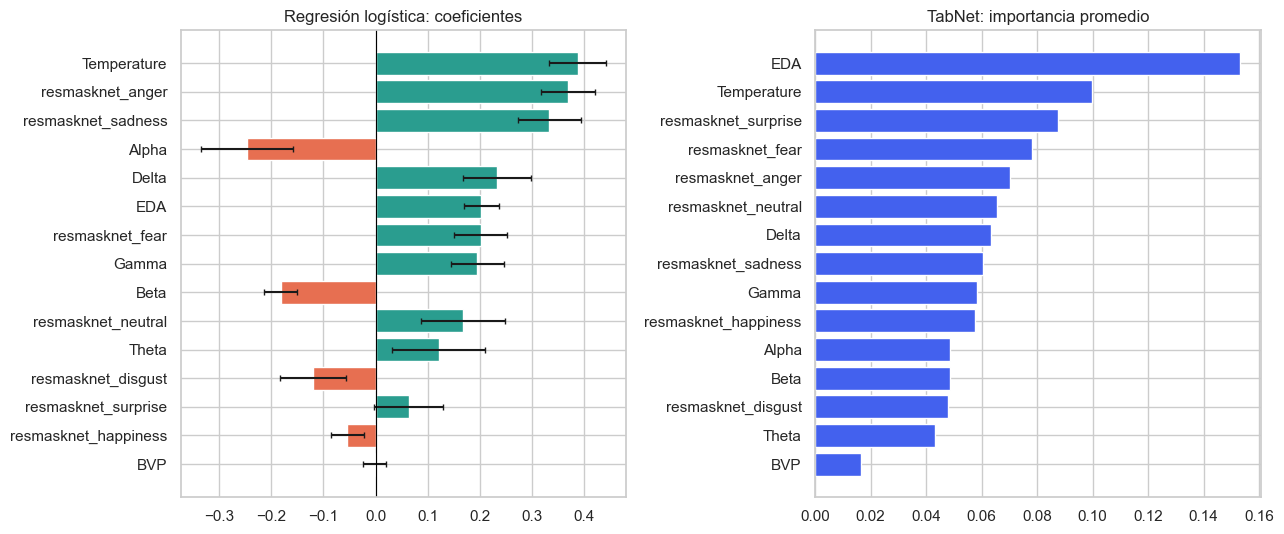

In [10]:
coefs = []
for tr, te in FOLDS:
    m = logreg().fit(w.iloc[tr][feature_cols], y[tr])
    coefs.append(m[-1].coef_[0])
coef = pd.DataFrame(coefs, columns=feature_cols)
resumen = pd.DataFrame({'coef_medio': coef.mean(), 'coef_sd': coef.std()}).sort_values('coef_medio', key=abs, ascending=True)

ncols = 2 if tabnet_imp else 1
fig, axes = plt.subplots(1, ncols, figsize=(6.5 * ncols, 5.5))
axes = np.atleast_1d(axes)
axes[0].barh(resumen.index, resumen['coef_medio'], xerr=resumen['coef_sd'],
             color=np.where(resumen['coef_medio'] > 0, '#2a9d8f', '#e76f51'), capsize=2)
axes[0].axvline(0, color='black', lw=0.8)
axes[0].set_title('Regresión logística: coeficientes')
if tabnet_imp:
    imp = pd.Series(np.mean(tabnet_imp, axis=0), index=feature_cols).sort_values()
    axes[1].barh(imp.index, imp.values, color='#4361ee')
    axes[1].set_title('TabNet: importancia promedio')
plt.tight_layout(); plt.show()

## 9. Cómo leer los resultados

- **Si los modelos con señales superan claramente el azar (0.5)**, las señales contienen algo de información sobre la concentración reportada.
- **Si no superan a "solo tipo de tarea"**, la concentración reportada depende más de la tarea que del estado medido de cada persona. Ese es un hallazgo reportable, no un fracaso.
- **"Tarea + señales" contra "solo tarea"** responde si las señales agregan información *dentro* de cada tarea.
- **Temperatura:** comparar "todas" contra "sin temperatura". Si casi no cambia, su dominio en Model2 venía de identificar a la persona y el momento de la prueba, no de la concentración.
- **La temperatura sigue funcionando como reloj aunque esté normalizada:** dentro de cada persona sube a lo largo de la prueba, y las tareas van siempre en el mismo orden. Un coeficiente positivo significa "más tarde en la prueba", no "más concentrado".
- **Varianza entre particiones (±):** con ~40 personas, diferencias menores a ~0.03 de AUC no son concluyentes.
- **Si se buscan hiperparámetros** (por ejemplo, búsqueda aleatoria), hacerlo **dentro** del entrenamiento de cada partición; nunca elegirlos viendo el resultado de prueba.

## 10. Resultados de nuestra corrida (focus ≥ 4, semilla 42)

_Si cambias `UMBRAL_FOCUS` o los datos, actualiza esta sección con tus números._

| Modelo | AUC |
|---|---|
| Base · solo tipo de tarea | **0.80** |
| Tarea + señales | **0.80** |
| Base · solo segundo de la prueba | 0.70 |
| Regresión logística · todas | 0.65 |
| Regresión logística · sin temperatura | 0.63 |
| Random forest · todas | 0.62 |
| Regresión logística · solo EEG | 0.59 |
| TabNet · todas | 0.58 |
| Base · clase mayoritaria | 0.50 |

**Lectura:**
1. **Con la etiqueta corregida, las señales sí tienen algo de información** (0.58–0.65, arriba del azar). El 0.40 de Model2 venía sobre todo de la etiqueta y de la falta de normalización.
2. **Ninguna combinación de señales supera a saber solo qué tarea es** (0.80). Y agregar las señales a la tarea **no mejora nada** (0.80 → 0.80): dentro de una misma tarea, las señales no distinguen quién se sintió más concentrado.
3. **El modelo más simple gana:** regresión logística (0.65) > random forest (0.62) > TabNet (0.58). Con ~40 personas no hay datos suficientes para que un modelo profundo aproveche su capacidad.
4. **Quitar la temperatura casi no cambia el resultado** (0.65 → 0.63): no era un indicador de concentración.
5. **Beta y alpha salen con coeficiente negativo:** más beta → menos probabilidad de "concentrado" reportado. Va en contra de lo que esperaba la literatura de concentración, lo que refuerza que el modelo capta la tarea o el momento, no un estado cerebral de concentración.

**Mensaje para el paper:** la concentración autorreportada en NPFC-Test se explica principalmente por la tarea; las señales de wearables, evaluadas con participantes nuevos, aportan poca información adicional.

---
# Parte 2 · Regresión logística: hiperparámetros y gráficas

1. **Sensibilidad:** qué hiperparámetros y decisiones de preparación cambian el resultado.
2. **Gráficas:** cómo separa la regresión logística a los concentrados de los no concentrados, y dónde falla.

Usa los mismos datos ya preparados arriba (`df`, `w`, `feature_cols`).

In [11]:
import warnings
from sklearn.metrics import roc_curve, confusion_matrix
from sklearn.compose import ColumnTransformer
warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', category=UserWarning)

# Colores (validados para daltonismo y contraste)
AZUL, NARANJA, GRIS, TINTA, TINTA2 = "#2a78d6", "#eb6834", "#8a8a85", "#1f1f1e", "#5f5e5a"
COL = {1: AZUL, 0: NARANJA}
NOMBRE = {1: "Concentrado", 0: "No concentrado"}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": "#c3c2b7", "axes.labelcolor": TINTA2, "xtick.color": TINTA2,
                     "ytick.color": TINTA2, "axes.grid": True, "grid.color": "#ecebe7", "grid.linewidth": 0.8,
                     "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlecolor": TINTA})

def preparar(umbral=UMBRAL_FOCUS, ventana=VENTANA_S, normalizar=True):
    """Misma preparación de la Parte 1, con parámetros para probar variantes."""
    d = df.copy()
    if normalizar:
        for c in feature_cols:
            d[c] = df.groupby('Subject_ID')[c].transform(lambda x: (x - x.mean()) / (x.std() if x.std() > 0 else 1))
    d['Ventana'] = d.groupby(['Subject_ID', 'Task_Num']).cumcount() // ventana
    out = (d.groupby(['Subject_ID', 'Task_Num', 'Ventana'])
             .agg({**{c: 'mean' for c in feature_cols}, 'Selfreport_focus': 'first', 'Segundo': 'mean'})
             .reset_index())
    out['Category'] = (out['Selfreport_focus'] >= umbral).astype(int)
    out['Task_Num_str'] = out['Task_Num'].astype(str)
    return out

def logreg_cfg(C=1.0, class_weight='balanced', penalty='l2'):
    if penalty == 'l1':
        lr = LogisticRegression(C=C, penalty='l1', solver='liblinear', class_weight=class_weight, max_iter=5000)
    else:  # L2 es el valor por defecto
        lr = LogisticRegression(C=C, class_weight=class_weight, max_iter=5000)
    return make_pipeline(StandardScaler(), lr)

def auc_cv(datos, modelo, cols):
    yy, gg = datos['Category'].values, datos['Subject_ID'].values
    aucs = []
    for tr, te in GroupKFold(N_SPLITS).split(datos, yy, gg):
        m = modelo().fit(datos.iloc[tr][cols], yy[tr])
        aucs.append(roc_auc_score(yy[te], m.predict_proba(datos.iloc[te][cols])[:, 1]))
    return np.mean(aucs), np.std(aucs)

## 11. Hiperparámetros usados en la Parte 1

| Modelo | Hiperparámetros |
|---|---|
| Regresión logística | `C=1.0` (fuerza de regularización, por defecto), `penalty='l2'`, `solver='lbfgs'`, `class_weight='balanced'`, `max_iter=2000`, con `StandardScaler` |
| Random forest | `n_estimators=300`, `min_samples_leaf=10`, `class_weight='balanced'`, `random_state=42` |
| TabNet | `n_d=16`, `n_a=16`, `n_steps=4`, `gamma=1.5`, `lambda_sparse=1e-4`, Adam `lr=0.02`, StepLR (`step_size=10`, `gamma=0.9`), `mask_type='entmax'`, `max_epochs=200`, `patience=20`, `batch_size=256`, `virtual_batch_size=64`, `weights=1` |
| Preparación | `UMBRAL_FOCUS=4`, `VENTANA_S=10`, normalización por persona, `N_SPLITS=5` |

**En Model3 no se ajustaron hiperparámetros**: se usaron valores por defecto o razonables. Abajo se mide cuáles importan.

### 11.1 Hiperparámetros de la regresión logística

In [12]:
filas = []
for C in [0.001, 0.01, 0.1, 1, 10, 100]:
    m, s = auc_cv(w, lambda C=C: logreg_cfg(C=C), feature_cols)
    filas.append({'Prueba': f'C = {C}', 'Grupo': 'C (regularización L2)', 'AUC': m, 'sd': s})
for pen in ['l1']:
    for C in [0.01, 0.1, 1]:
        m, s = auc_cv(w, lambda C=C: logreg_cfg(C=C, penalty='l1'), feature_cols)
        filas.append({'Prueba': f'L1, C = {C}', 'Grupo': 'Penalización L1', 'AUC': m, 'sd': s})
m, s = auc_cv(w, lambda: logreg_cfg(class_weight=None), feature_cols)
filas.append({'Prueba': 'Sin class_weight', 'Grupo': 'Balance de clases', 'AUC': m, 'sd': s})
hp = pd.DataFrame(filas)
hp.round(3)

,Prueba,Grupo,AUC,sd
0,C = 0.001,C (regularización L2),0.644,0.046
1,C = 0.01,C (regularización L2),0.650,0.050
2,C = 0.1,C (regularización L2),0.651,0.053
3,C = 1,C (regularización L2),0.651,0.053
4,C = 10,C (regularización L2),0.651,0.053
5,C = 100,C (regularización L2),0.651,0.053
6,"L1, C = 0.01",Penalización L1,0.630,0.048
7,"L1, C = 0.1",Penalización L1,0.648,0.052
8,"L1, C = 1",Penalización L1,0.651,0.053
9,Sin class_weight,Balance de clases,0.651,0.053


### 11.2 Decisiones de preparación (con la regresión logística por defecto)

In [13]:
filas = []
for umbral in [3, 4, 5]:
    ww = preparar(umbral=umbral)
    m, s = auc_cv(ww, logreg_cfg, feature_cols)
    filas.append({'Prueba': f'Umbral focus ≥ {umbral} ({ww.Category.mean():.0%} concentrado)', 'Grupo': 'Umbral de la etiqueta', 'AUC': m, 'sd': s})
for v in [1, 5, 10, 30]:
    m, s = auc_cv(preparar(ventana=v), logreg_cfg, feature_cols)
    filas.append({'Prueba': f'Ventana de {v} s', 'Grupo': 'Tamaño de ventana', 'AUC': m, 'sd': s})
for norm in [True, False]:
    m, s = auc_cv(preparar(normalizar=norm), logreg_cfg, feature_cols)
    filas.append({'Prueba': 'Normalizado por persona' if norm else 'Sin normalizar', 'Grupo': 'Normalización', 'AUC': m, 'sd': s})
prep = pd.DataFrame(filas)
prep.round(3)

,Prueba,Grupo,AUC,sd
0,Umbral focus ≥ 3 (80% concentrado),Umbral de la etiqueta,0.645,0.070
1,Umbral focus ≥ 4 (54% concentrado),Umbral de la etiqueta,0.651,0.053
2,Umbral focus ≥ 5 (23% concentrado),Umbral de la etiqueta,0.542,0.052
3,Ventana de 1 s,Tamaño de ventana,0.637,0.065
4,Ventana de 5 s,Tamaño de ventana,0.652,0.024
5,Ventana de 10 s,Tamaño de ventana,0.651,0.053
6,Ventana de 30 s,Tamaño de ventana,0.660,0.048
7,Normalizado por persona,Normalización,0.651,0.053
8,Sin normalizar,Normalización,0.545,0.052


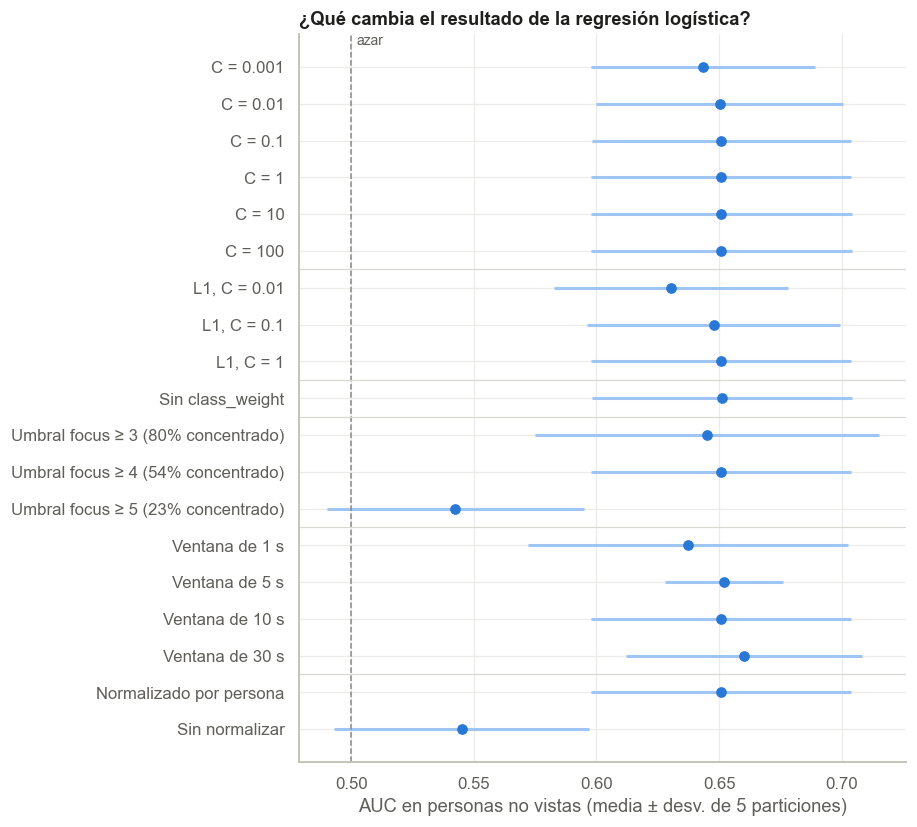

Qué tanto mueve el AUC cada grupo (máximo − mínimo):
Grupo
Umbral de la etiqueta    0.109
Normalización            0.106
Tamaño de ventana        0.023
Penalización L1          0.020
C (regularización L2)    0.007
Balance de clases        0.000


In [14]:
tabla = pd.concat([hp, prep], ignore_index=True)
rango = tabla.groupby('Grupo')['AUC'].agg(lambda x: x.max() - x.min()).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(8.5, 0.32 * len(tabla) + 1.6))
orden = tabla.iloc[::-1].reset_index(drop=True)
ypos = np.arange(len(orden))
ax.errorbar(orden['AUC'], ypos, xerr=orden['sd'], fmt='o', color=AZUL, ecolor='#9ec5f4', elinewidth=2, capsize=0, markersize=6)
ax.set_yticks(ypos, orden['Prueba'])
ax.axvline(0.5, color=GRIS, ls='--', lw=1)
ax.text(0.502, len(orden) - 0.4, 'azar', color=TINTA2, fontsize=9)
for g in orden['Grupo'].unique()[:-1]:
    ultimo = orden.index[orden['Grupo'] == g].max()
    ax.axhline(ultimo + 0.5, color='#d9d8d2', lw=0.8)
ax.set_xlabel('AUC en personas no vistas (media ± desv. de 5 particiones)')
ax.set_title('¿Qué cambia el resultado de la regresión logística?', loc='left')
plt.tight_layout(); plt.show()

print("Qué tanto mueve el AUC cada grupo (máximo − mínimo):")
print(rango.round(3).to_string())

## 12. Predicciones fuera de muestra

Cada ventana se predice con un modelo que **no vio a esa persona** (GroupKFold). Se guardan las probabilidades de tres modelos: solo señales, solo tarea y tarea + señales.

Aquí el AUC se calcula juntando las predicciones de las 5 particiones, por eso puede diferir un poco del promedio por partición de la Parte 1 (p. ej., 0.77 vs 0.80 en "solo tarea").

In [15]:
y, g = w['Category'].values, w['Subject_ID'].values
FOLDS = list(GroupKFold(N_SPLITS).split(w, y, g))

def tarea():
    return make_pipeline(OneHotEncoder(handle_unknown='ignore'), LogisticRegression(max_iter=2000, class_weight='balanced'))
def tarea_senales():
    pre = ColumnTransformer([('t', OneHotEncoder(handle_unknown='ignore'), ['Task_Num_str']), ('s', StandardScaler(), feature_cols)])
    return make_pipeline(pre, LogisticRegression(max_iter=2000, class_weight='balanced'))

modelos = {'Señales (regresión logística)': (logreg_cfg, feature_cols),
           'Solo tipo de tarea': (tarea, ['Task_Num_str']),
           'Tarea + señales': (tarea_senales, ['Task_Num_str'] + feature_cols)}
oof = {k: np.zeros(len(w)) for k in modelos}
coefs = []
for tr, te in FOLDS:
    for k, (f, cols) in modelos.items():
        m = f().fit(w.iloc[tr][cols], y[tr])
        oof[k][te] = m.predict_proba(w.iloc[te][cols])[:, 1]
        if k == 'Señales (regresión logística)':
            coefs.append(m[-1].coef_[0])
w['p_senales'] = oof['Señales (regresión logística)']
for k in modelos:
    print(f"{k:32s} AUC fuera de muestra = {roc_auc_score(y, oof[k]):.3f}")

Señales (regresión logística)    AUC fuera de muestra = 0.647
Solo tipo de tarea               AUC fuera de muestra = 0.772
Tarea + señales                  AUC fuera de muestra = 0.778


## 13. ¿Qué variables empujan hacia "concentrado"?

Coeficientes convertidos a **razón de momios** (odds ratio): cuánto se multiplica la probabilidad relativa de "concentrado" cuando la variable sube una desviación estándar *respecto al nivel normal de esa persona*. Mayor a 1 = empuja a concentrado; menor a 1 = empuja a no concentrado. Las barras de error muestran la variación entre las 5 particiones.

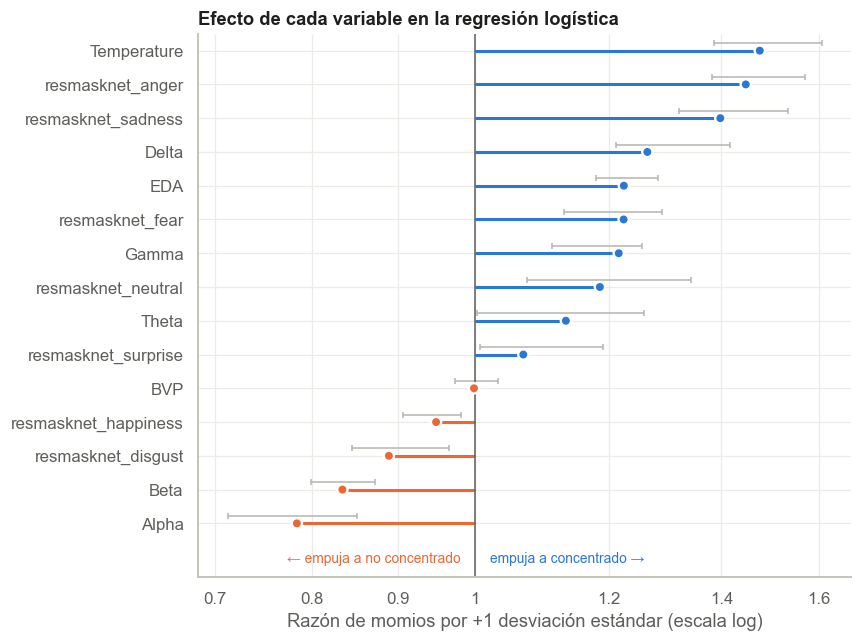

In [16]:
cf = pd.DataFrame(coefs, columns=feature_cols)
OR = np.exp(cf)
res = pd.DataFrame({'OR': OR.mean(), 'lo': OR.min(), 'hi': OR.max()}).sort_values('OR')

fig, ax = plt.subplots(figsize=(8, 6))
ypos = np.arange(len(res))
col = [AZUL if v > 1 else NARANJA for v in res['OR']]
ax.hlines(ypos, 1, res['OR'], color=col, lw=2)
ax.scatter(res['OR'], ypos, color=col, s=45, zorder=3, edgecolor='white', linewidth=1.5)
ax.errorbar(res['OR'], ypos + 0.22, xerr=[res['OR'] - res['lo'], res['hi'] - res['OR']], fmt='none', ecolor='#b5b4ad', lw=1, capsize=2, zorder=2)
ax.axvline(1, color=TINTA2, lw=1)
ax.set_yticks(ypos, res.index)
ax.set_xscale('log')
ax.set_xticks([0.7, 0.8, 0.9, 1, 1.2, 1.4, 1.6], ['0.7', '0.8', '0.9', '1', '1.2', '1.4', '1.6'])
ax.minorticks_off()
ax.set_ylim(-1.6, len(res) - 0.5)
ax.text(1.02, -1.15, 'empuja a concentrado →', color=AZUL, fontsize=9)
ax.text(0.98, -1.15, '← empuja a no concentrado', color=NARANJA, fontsize=9, ha='right')
ax.set_xlabel('Razón de momios por +1 desviación estándar (escala log)')
ax.set_title('Efecto de cada variable en la regresión logística', loc='left')
plt.tight_layout(); plt.show()

## 14. ¿Qué tan bien separa a los dos grupos?

Si el modelo separara bien, los concentrados tendrían probabilidades cerca de 1 y los no concentrados cerca de 0. Cuanto más se enciman las dos distribuciones, peor distingue.

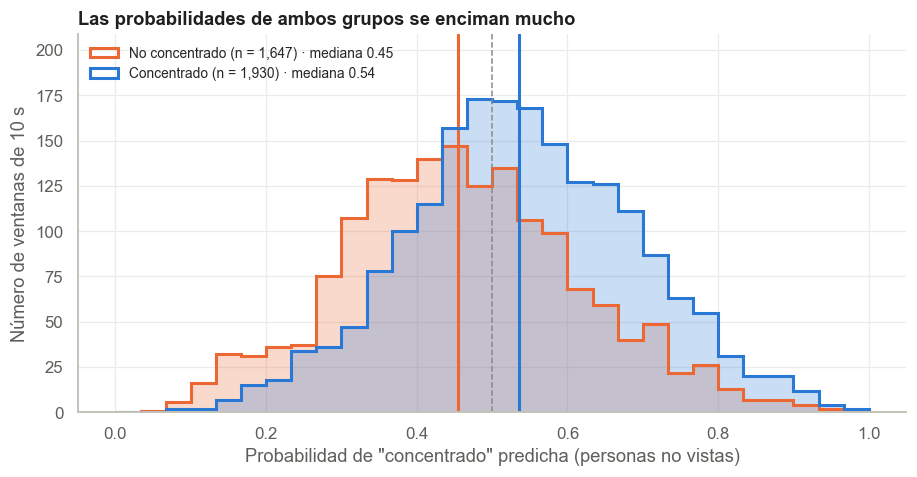

In [17]:
fig, ax = plt.subplots(figsize=(8.5, 4.5))
bins = np.linspace(0, 1, 31)
for k in [0, 1]:
    p = w.loc[w.Category == k, 'p_senales']
    ax.hist(p, bins=bins, color=COL[k], alpha=0.25, histtype='stepfilled')
    ax.hist(p, bins=bins, color=COL[k], lw=2, histtype='step', label=f"{NOMBRE[k]} (n = {len(p):,}) · mediana {p.median():.2f}")
    ax.axvline(p.median(), color=COL[k], lw=2, ls='-')
ax.axvline(0.5, color=GRIS, ls='--', lw=1)
ax.set_xlabel('Probabilidad de "concentrado" predicha (personas no vistas)')
ax.set_ylabel('Número de ventanas de 10 s')
ax.set_title('Las probabilidades de ambos grupos se enciman mucho', loc='left')
ax.legend(frameon=False, loc='upper left', fontsize=9)
ax.set_ylim(0, ax.get_ylim()[1] * 1.15)
plt.tight_layout(); plt.show()

## 15. Curvas ROC: señales vs. tarea

Cada curva muestra el balance entre detectar concentrados (eje vertical) y equivocarse con los no concentrados (eje horizontal). Mientras más se acerque a la esquina superior izquierda, mejor. La diagonal es adivinar al azar.

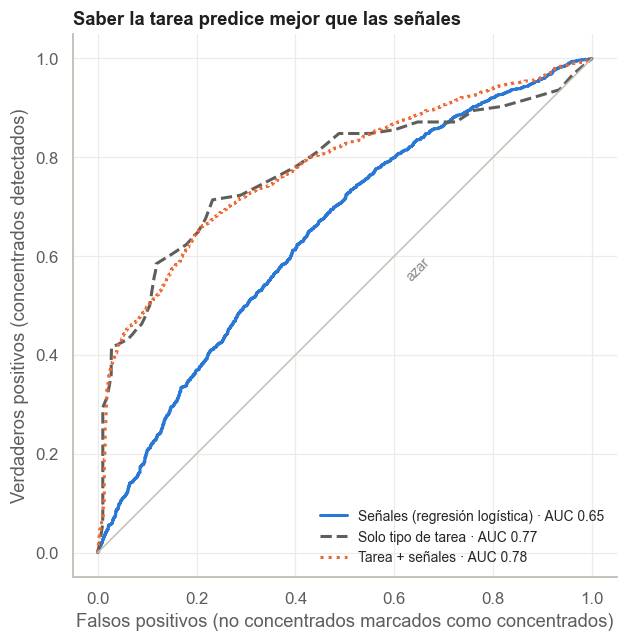

In [18]:
fig, ax = plt.subplots(figsize=(6, 6))
estilos = {'Señales (regresión logística)': (AZUL, '-'), 'Solo tipo de tarea': (TINTA2, '--'), 'Tarea + señales': (NARANJA, ':')}
for k, (c, ls) in estilos.items():
    fpr, tpr, _ = roc_curve(y, oof[k])
    ax.plot(fpr, tpr, color=c, ls=ls, lw=2, label=f"{k} · AUC {roc_auc_score(y, oof[k]):.2f}")
ax.plot([0, 1], [0, 1], color='#c3c2b7', lw=1)
ax.text(0.62, 0.55, 'azar', color=GRIS, fontsize=9, rotation=45)
ax.set_xlabel('Falsos positivos (no concentrados marcados como concentrados)')
ax.set_ylabel('Verdaderos positivos (concentrados detectados)')
ax.set_title('Saber la tarea predice mejor que las señales', loc='left')
ax.legend(frameon=False, loc='lower right', fontsize=9)
ax.set_aspect('equal')
plt.tight_layout(); plt.show()

## 16. Matriz de confusión (umbral 0.5)

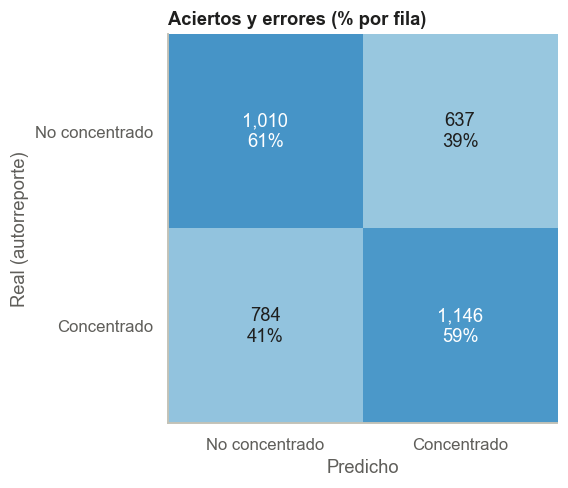

In [19]:
pred = (w['p_senales'] >= 0.5).astype(int)
cm = confusion_matrix(y, pred, labels=[0, 1])
cmn = cm / cm.sum(axis=1, keepdims=True)

fig, ax = plt.subplots(figsize=(5.5, 4.6))
ax.imshow(cmn, cmap='Blues', vmin=0, vmax=1)
ax.grid(False)
for i in range(2):
    for j in range(2):
        ax.text(j, i, f"{cm[i, j]:,}\n{cmn[i, j]:.0%}", ha='center', va='center', fontsize=12,
                color='white' if cmn[i, j] > 0.55 else TINTA)
ax.set_xticks([0, 1], ['No concentrado', 'Concentrado'])
ax.set_yticks([0, 1], ['No concentrado', 'Concentrado'])
ax.set_xlabel('Predicho'); ax.set_ylabel('Real (autorreporte)')
ax.set_title('Aciertos y errores (% por fila)', loc='left')
plt.tight_layout(); plt.show()

## 17. Las dos variables más influyentes

Se toman las dos variables con mayor efecto y se ajusta una regresión logística solo con ellas para dibujar la **frontera de decisión** (línea donde la probabilidad es 50%). Se muestra una muestra de puntos para que se lea mejor.

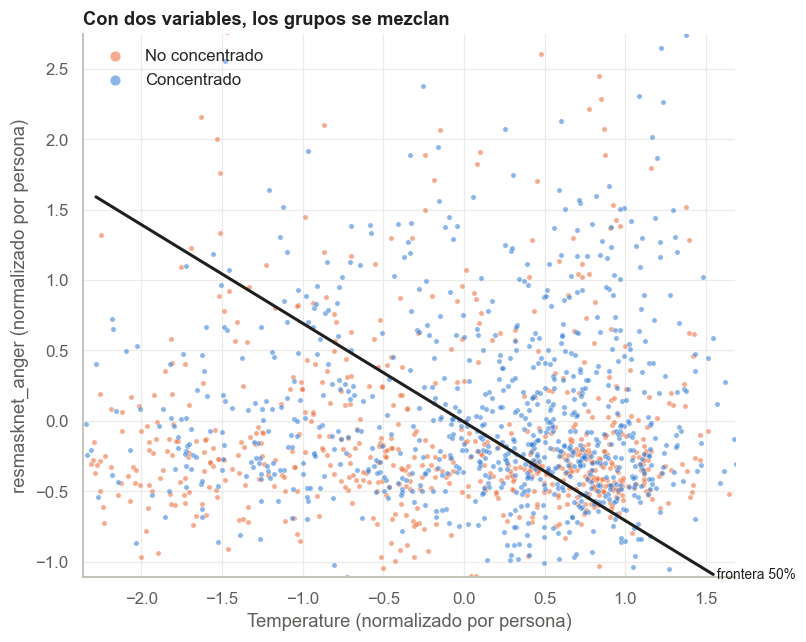

AUC con solo ['Temperature', 'resmasknet_anger']: 0.625


In [20]:
top2 = cf.mean().abs().sort_values(ascending=False).index[:2].tolist()
m2 = logreg_cfg().fit(w[top2], y)
sc, lr = m2[0], m2[-1]
muestra = w.sample(min(1500, len(w)), random_state=0)

fig, ax = plt.subplots(figsize=(7.5, 6))
for k in [0, 1]:
    s = muestra[muestra.Category == k]
    ax.scatter(s[top2[0]], s[top2[1]], s=12, color=COL[k], alpha=0.55, label=NOMBRE[k], edgecolor='white', linewidth=0.4)
xs = np.linspace(muestra[top2[0]].quantile(0.01), muestra[top2[0]].quantile(0.99), 50)
# frontera: b0 + b1*(x-m1)/s1 + b2*(y-m2)/s2 = 0
b0, (b1, b2) = lr.intercept_[0], lr.coef_[0]
ys = sc.mean_[1] + sc.scale_[1] * (-(b0 + b1 * (xs - sc.mean_[0]) / sc.scale_[0]) / b2)
ax.plot(xs, ys, color=TINTA, lw=2)
ax.text(xs[-1], ys[-1], ' frontera 50%', color=TINTA, fontsize=9, va='center')
ax.set_xlim(muestra[top2[0]].quantile(0.005), muestra[top2[0]].quantile(0.995))
ax.set_ylim(muestra[top2[1]].quantile(0.005), muestra[top2[1]].quantile(0.995))
ax.set_xlabel(f"{top2[0]} (normalizado por persona)")
ax.set_ylabel(f"{top2[1]} (normalizado por persona)")
ax.set_title('Con dos variables, los grupos se mezclan', loc='left')
ax.legend(frameon=False, markerscale=2)
plt.tight_layout(); plt.show()
print(f"AUC con solo {top2}: {auc_cv(w, logreg_cfg, top2)[0]:.3f}")

## 18. ¿El modelo sigue a la persona o a la tarea?

Por tarea: el porcentaje real de ventanas marcadas como "concentrado" (según el autorreporte) contra la probabilidad promedio que predice el modelo de señales. Si los puntos suben y bajan juntos, el modelo está captando sobre todo **qué tarea es**.

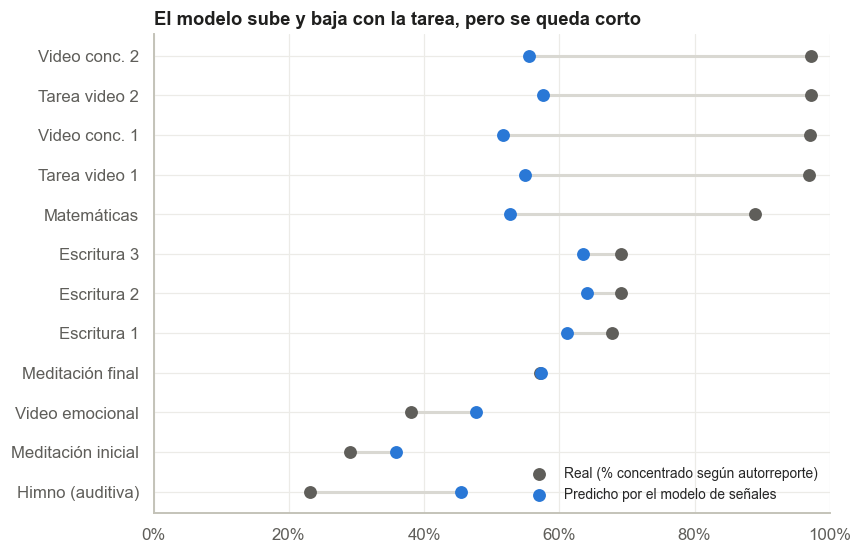

Correlación por tarea entre real y predicho: 0.55


In [21]:
nombres = {2.1: 'Meditación inicial', 3.1: 'Matemáticas', 4.1: 'Himno (auditiva)', 5.1: 'Video conc. 1',
           5.2: 'Tarea video 1', 5.3: 'Video conc. 2', 5.4: 'Tarea video 2', 6.1: 'Video emocional',
           7.2: 'Escritura 1', 7.3: 'Escritura 2', 7.4: 'Escritura 3', 8.1: 'Meditación final'}
pt = w.groupby('Task_Num').agg(real=('Category', 'mean'), pred=('p_senales', 'mean')).sort_values('real')
pt.index = [nombres.get(t, t) for t in pt.index]

fig, ax = plt.subplots(figsize=(8, 5.2))
ypos = np.arange(len(pt))
ax.hlines(ypos, pt['pred'], pt['real'], color='#d9d8d2', lw=2)
ax.scatter(pt['real'], ypos, color=TINTA2, s=55, zorder=3, label='Real (% concentrado según autorreporte)')
ax.scatter(pt['pred'], ypos, color=AZUL, s=55, zorder=3, label='Predicho por el modelo de señales')
ax.set_yticks(ypos, pt.index)
ax.set_xlim(0, 1)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))
ax.set_title('El modelo sube y baja con la tarea, pero se queda corto', loc='left')
ax.legend(frameon=False, loc='lower right', fontsize=9)
plt.tight_layout(); plt.show()
print(f"Correlación por tarea entre real y predicho: {pt['real'].corr(pt['pred']):.2f}")

## 19. Resumen

**Hiperparámetros**
- En la Parte 1 **no se ajustaron hiperparámetros**; se usaron valores por defecto.
- Los hiperparámetros de la regresión logística **casi no cambian nada**: `C` entre 0.001 y 100 da AUC de 0.64 a 0.65; quitar `class_weight` no cambia nada; L1 solo empeora si es muy fuerte (C = 0.01 → 0.60).
- **Lo que sí importa son las decisiones de preparación:**
  - **Umbral de la etiqueta:** ≥ 3 y ≥ 4 dan ~0.65; ≥ 5 cae a 0.54 (solo 23% de positivos y una etiqueta más ruidosa).
  - **Normalizar por persona:** sin normalizar cae a 0.56. Es la corrección que más pesa después del umbral.
  - **Tamaño de ventana:** casi no importa (0.64–0.65 entre 1 y 30 s).

**Gráficas**
- **Efectos:** temperatura, enojo y tristeza faciales empujan hacia "concentrado"; alpha, beta y disgusto hacia "no concentrado". Beta en negativo contradice la literatura de concentración.
- **Separación:** las medianas de probabilidad son 0.45 (no concentrado) y 0.54 (concentrado): las distribuciones se enciman casi por completo.
- **ROC:** la curva de "solo tarea" queda por encima de la de señales; agregar señales a la tarea casi no la mueve.
- **Matriz de confusión:** ~60% de aciertos en cada clase.
- **Dos variables:** con temperatura y enojo, los grupos se mezclan; la frontera apenas los separa.
- **Por tarea:** el modelo sube y baja en la misma dirección que el autorreporte (correlación 0.54), pero sus predicciones van solo de ~36% a ~59%, mientras que lo real va de 23% a 97%. Capta un poco de la tarea, no el estado de cada persona.

**Para el paper:** la regresión logística sirve como modelo interpretable para mostrar *por qué* las señales predicen poco: los grupos se enciman, el efecto de cada variable es pequeño (razones de momios entre 0.8 y 1.5) y lo poco que capta coincide con el patrón de las tareas.